# Data Aggregation, Auto-Correlation, Bias and Precision

Julian Hsu

Created: 30-mar-2023

Last Editted: 06-nov-2026

Often we aggregate daily-level data in order to decrease statistical noise, reduce our computational cost, or both. This notebook asks one question: **how does aggregating daily data into larger time buckets affect the bias and the precision of an experiment's estimated treatment effect, and how does that depend on how auto-correlated the outcome is over time?**

We simulate panel data where we track users over time, estimate the effect of a treatment with a two-way fixed effects (TWFE) regression that controls for the lagged outcome, and compare three levels of aggregation:
1. **Daily**: the data as generated.
2. **3-day**: outcomes and covariates averaged over each 3-day bucket.
3. **Weekly**: outcomes and covariates averaged over each 7-day bucket.

We cross these with three levels of auto-correlation (AR = 0, 0.10, 0.50) and summarize the results with two heatmaps: one for bias and one for precision (the standard error relative to the daily, no auto-correlation base case).

### Summary of results
**Aggregation is cheap when outcomes are not auto-correlated, and expensive when they are.**
- *Daily data* stays accurate at every level of auto-correlation (bias of 2% or less of the true effect), and its standard error is only 13% larger at AR = 0.5.
- *With no auto-correlation (AR = 0)*, moving to 3-day or weekly buckets leaves bias small (under 3%) and makes the standard error 13% and 27% larger, respectively. Aggregation costs some precision.
- *With strong auto-correlation (AR = 0.5)*, 3-day and weekly buckets are badly biased (about 48% and 82% of the true effect) and their standard errors are 1.8x and 2.4x the base case. Aggregation costs both accuracy and precision, and the lower standard error we hoped for does not show up.

So the more persistent your outcome is over time, the more you should keep your analysis at the daily level. These results come from one simulated setup (100 simulation rounds, 100 users, half treated, bucket averages, and a regression with the lagged outcome), so treat the exact magnitudes as illustrative.


### Model Setup

For our examples, we will generate synthetic panel data of $N$ users observed daily.

Specifically, we are going model outcomes $y_{it}$ as:

$$y_{it} = \alpha y_{i,t-1} + \beta X_{it} + \gamma W_{it} + \nu_i + \tau_{it} + \epsilon_{it} $$

Where $\alpha$ tells us how auto-regressive the series is. This is the auto-correlation setting we vary: 0, 0.10 and 0.50.

Where $X_{it}$ is a sparse, noisy covariate.

Where $\gamma$ is our treatment effect of interest, and $W_{it}$ equals one for treated users after the treatment starts.

Where $\nu_i$ is a unit-level fixed effect and $\tau_{it}$ is a day-specific shock.

Where $\epsilon_{it} \sim N(0,\sigma)$ is unexplainable noise.

Half of the users are treated. The data covers a number of pre-treatment and post-treatment "periods", where each period is 21 days long. Using 21 days means the treatment start date lines up with the start of every 1-day, 3-day and 7-day bucket, so no bucket mixes pre-treatment and post-treatment days.


In [10]:
import numpy as np
import pandas as pd

%matplotlib inline

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from linearmodels.panel import PanelOLS

import warnings
warnings.filterwarnings('ignore') ## linearmodels warns about the missing first lag in every regression


In [11]:
def dgp(N=None, ## How many observations
        preT=None, ## How many pre-treatment time periods
        pstT=None, ## How many post-treatment time periods
        X_var=None, ## what is the variance in X
        ar=0.50, ## AR strength
        atet=1, ## Treatment effect
        error_std=None, ## How much idiosyncractic error there is
        micro_periods=21 ## Days per period. 21 = lcm(1,3,7), so daily, 3-day and weekly buckets all line up with treatment start
       ):
    '''
    Generate a daily panel. Each time period is made up of `micro_periods` days.
    All random draws are made up front (in a fixed order, independent of `ar`) so that
    calling np.random.seed(s) before dgp() gives the same noise for every AR setting.
    '''
    totalT = (preT+pstT)*micro_periods

    ## Unit fixed effects and treated units (half of the units are treated)
    unit_effect = np.random.uniform(-1,1,N)
    treated_unit = (np.arange(N) < N//2).astype(float)

    ## Covariates, day-specific shocks, and idiosyncratic errors for every day x unit
    X = np.random.normal(0,X_var,(totalT,N)) * np.random.choice(2,(totalT,N),p=[0.95,0.05])
    t_effect = np.random.uniform(-1,1,(totalT,N))
    eps = np.random.normal(0,error_std,(totalT,N))

    ## Treatment is on for treated units from the first post-treatment day onwards
    post = (np.arange(totalT) >= preT*micro_periods).astype(float)
    W = post[:,None]*treated_unit[None,:]

    ## Construct y recursively so that it can depend on yesterday's outcome
    y = np.zeros((totalT,N))
    prey = np.zeros(N)
    for t in range(totalT):
        y[t] = ar*prey + X[t] + atet*W[t] + t_effect[t] + unit_effect + eps[t]
        prey = y[t]

    return pd.DataFrame({'unitid':np.tile(np.arange(N),totalT),
                         't':np.repeat(np.arange(totalT),N),
                         'X':X.ravel(),
                         'W':W.ravel(),
                         'post':np.repeat(post,N),
                         'y':y.ravel()})


In [12]:
'''
Code up a DiD function using the PanelOLS function.
The data is aggregated into buckets of `bucket` days before estimation. bucket=1 is the daily data.
'''

def did_twfe(data=None, bucket=1, aggstat='mean'):
    ## Aggregate days into buckets. Treatment starts at the start of a bucket, so W is constant within a bucket.
    dg = (data.assign(b=data['t']//bucket)
              .groupby(['unitid','b'])
              .agg(X=('X',aggstat), W=('W','max'), y=('y',aggstat)))
    ## Control for the lagged (bucket-level) outcome
    XX = sm.add_constant(pd.concat([dg[['X','W']], dg.groupby(['unitid'])['y'].shift().rename('y_lag')], axis=1))
    m = PanelOLS(dependent=dg['y'],
                 exog=XX,
                 entity_effects=True,
                 time_effects=True)
    res = m.fit()
    return pd.DataFrame(index=[0], data={'atet':res.params['W'],
                                         'se':res.std_errors['W']})


In [13]:
## Quick check on one simulated dataset: daily vs. weekly estimates
df = dgp(N=30,preT=5,pstT=3,ar=0.5,atet=2, X_var=1,error_std=1)
pd.concat([did_twfe(data=df, bucket=b).assign(bucket=b) for b in [1,3,7]])


,atet,se,bucket
0,2.090684,0.082352,1
0,2.948391,0.132825,3
0,3.583102,0.172533,7


### Illustration: What Aggregation Does to One Simulated Dataset
Before running the full simulation, we look at a single simulated dataset (100 users, half treated, AR = 0.5, true effect 2) and aggregate it into 3-day and 7-day averages. We plot the average outcome of the treated and control units at each granularity, and then the difference between them after treatment starts.


In [14]:
## One simulated dataset (AR = 0.5, true effect = 2), later aggregated into daily, 3-day and 7-day averages
ill_N, ill_preT, ill_pstT, ill_atet, ill_ar = 100, 5, 3, 2, 0.50
ill_t0 = ill_preT*21 ## first treated day (each period is 21 days long)
ill_buckets = {1:'Daily', 3:'3-day average', 7:'7-day average'} ## days per bucket
ill_c_tr, ill_c_ct = '#d1495b', '#00798c'
ill_style = {'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False,
             'axes.grid':True, 'grid.alpha':.25}

np.random.seed(42276)
ill_df = dgp(N=ill_N, preT=ill_preT, pstT=ill_pstT, ar=ill_ar, atet=ill_atet, X_var=0.25, error_std=1)

def ill_bucket_means(data, bucket):
    '''Average outcome of all treated and all control units in each bucket. x is the bucket midpoint in days.'''
    d = data.assign(grp=np.where(data['unitid'] < ill_N//2, 'Treated', 'Control'), b=data['t']//bucket)
    g = d.groupby(['grp','b'])['y'].mean().unstack('grp')
    g['x'] = g.index*bucket + (bucket-1)/2
    g['gap'] = g['Treated'] - g['Control']
    return g


#### Illustration 1: Treated vs control trends at each granularity
Each panel shows the average outcome across all control units and across all treated units, at a different level of aggregation: daily, 3-day average and 7-day average. The dashed vertical line marks when treatment starts. Dots mark the bucket averages.


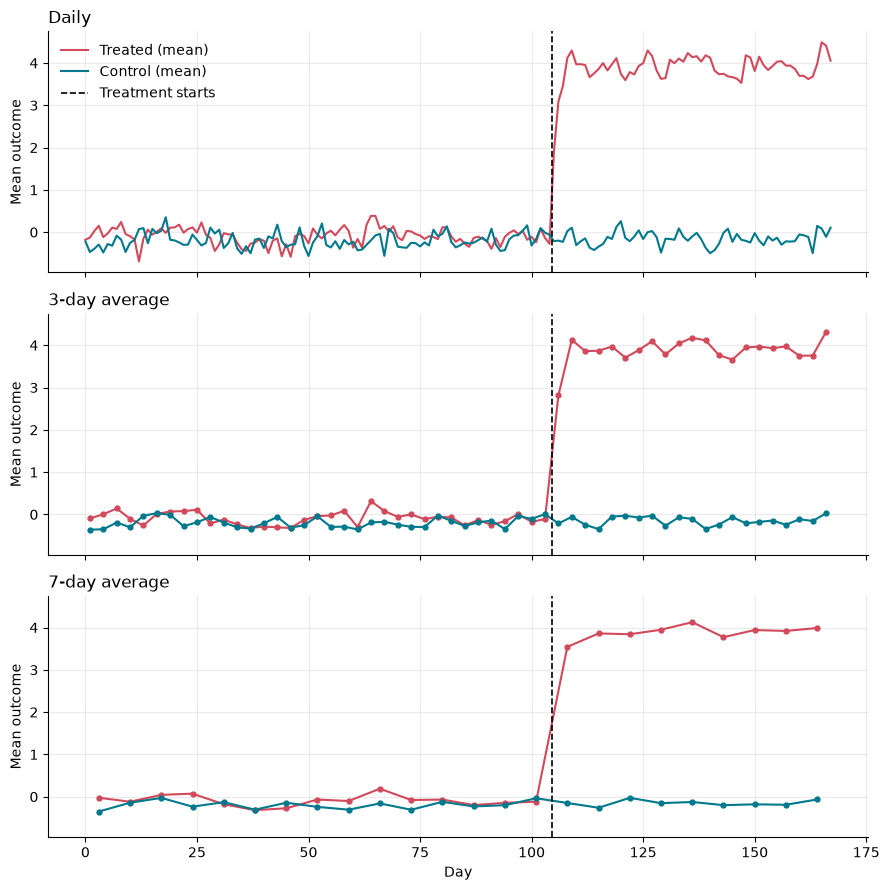

In [15]:
with plt.rc_context(ill_style):
    fig, axes = plt.subplots(len(ill_buckets), 1, figsize=(9,9), sharex=True, sharey=True)
    for ax, (b, lab) in zip(axes, ill_buckets.items()):
        g = ill_bucket_means(ill_df, b)
        mk = 'o' if b > 1 else None
        ax.plot(g['x'], g['Treated'], color=ill_c_tr, marker=mk, ms=3.5, label='Treated (mean)')
        ax.plot(g['x'], g['Control'], color=ill_c_ct, marker=mk, ms=3.5, label='Control (mean)')
        ax.axvline(ill_t0-.5, color='k', ls='--', lw=1.2, label='Treatment starts')
        ax.set_title(lab, loc='left')
        ax.set_ylabel('Mean outcome')
    axes[-1].set_xlabel('Day')
    axes[0].legend(frameon=False, loc='upper left')
    fig.tight_layout()
    plt.show()


#### Illustration 2: The treated-control difference after treatment
Using the same data and only the average trends, each panel plots the difference between the treated and control averages after treatment starts, at each granularity. The dotted line is the true treatment effect.


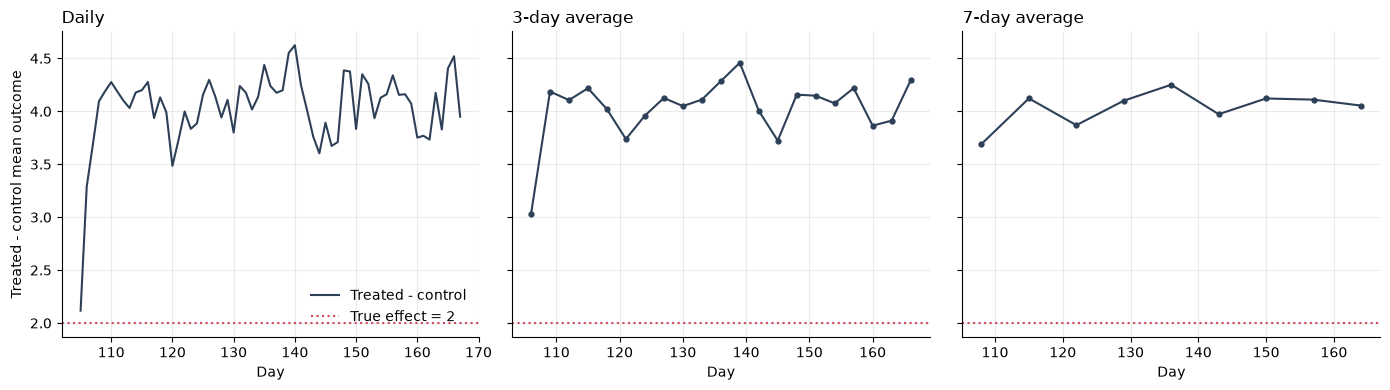

In [16]:
with plt.rc_context(ill_style):
    fig, axes = plt.subplots(1, len(ill_buckets), figsize=(14,4), sharey=True)
    for ax, (b, lab) in zip(axes, ill_buckets.items()):
        g = ill_bucket_means(ill_df, b)
        g = g[g.index*b >= ill_t0] ## keep only buckets after treatment starts
        ax.plot(g['x'], g['gap'], color='#2e4057', marker='o' if b > 1 else None, ms=3.5, label='Treated - control')
        ax.axhline(ill_atet, color=ill_c_tr, ls=':', lw=1.5, label='True effect = {0}'.format(ill_atet))
        ax.set_title(lab, loc='left')
        ax.set_xlabel('Day')
    axes[0].set_ylabel('Treated - control mean outcome')
    axes[0].legend(frameon=False, loc='lower right')
    fig.tight_layout()
    plt.show()


### Simulation Design
We simulate data many times and, for each simulated dataset, estimate the treatment effect at three levels of aggregation. We repeat this for three levels of auto-correlation. The true treatment effect is 2.

1. The strength of the AR relationship: (`ar_list`)
2. The aggregation level, in days per bucket: (`bucket_list`). One bucket = daily, 3 = three-day average, 7 = weekly average.

Within a simulation round, every AR setting uses the same random draws, so differences across AR settings are not due to different noise.


In [ ]:
ar_list = [0, 0.10, 0.50]
bucket_list = [1, 3, 7] ## days per bucket
bucket_labels = {1:'Daily', 3:'3-Day', 7:'Weekly'}


In [ ]:
atet_ = 2
sim_rounds = 5
seed0 = 42276 ## reproducibility

rows = []
for ar_ in ar_list:
    for s in range(sim_rounds):
        np.random.seed(seed0 + s) ## same random draws for every AR setting
        df = dgp(N=100, preT=5, pstT=3, ar=ar_, atet=atet_, X_var=0.25, error_std=1)
        for b in bucket_list:
            twfe_result = did_twfe(data=df, bucket=b)
            rows.append({'ar':ar_, 'bucket':b, 'sim':s,
                         'atet':twfe_result['atet'].iloc[0], 'se':twfe_result['se'].iloc[0]})

df_r = pd.DataFrame(rows)
df_r['diff'] = df_r['atet'] - atet_


In [ ]:
## Bias: absolute average error as a share of the true effect, by AR setting x aggregation level
bias_tbl = (df_r.groupby(['ar','bucket'])['diff'].mean().abs() / atet_).unstack('bucket')

## Precision: average standard error, relative to the base case (no auto-correlation, daily data)
se_mean = df_r.groupby(['ar','bucket'])['se'].mean().unstack('bucket')
se_tbl = se_mean / se_mean.loc[ar_list[0], bucket_list[0]]

for tbl in [bias_tbl, se_tbl]:
    tbl.columns = [bucket_labels[b] for b in tbl.columns]
    tbl.index = ['AR = {0}'.format(a) for a in tbl.index]


### Heatmap 1: Bias
Each cell is the absolute average error of the estimated treatment effect, as a percent of the true effect (2), for one combination of auto-correlation (rows) and aggregation level (columns). The top-left cell is the base case: no auto-correlation, daily data.


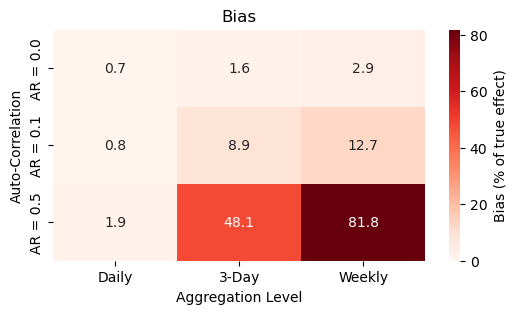

In [ ]:
fig, ax = plt.subplots(figsize=(6,3))
sns.heatmap(bias_tbl*100, annot=True, fmt='.1f', cmap='Reds', vmin=0, ax=ax,
            cbar_kws={'label':'Bias (% of true effect)'})
ax.set_xlabel('Aggregation Level')
ax.set_ylabel('Auto-Correlation')
ax.set_title('Bias')
plt.show()


### Heatmap 2: Precision
Each cell is the average standard error of the estimated treatment effect, divided by the average standard error in the base case (no auto-correlation, daily data). The base cell is therefore 1.00; values above 1 mean less precision than the base case.


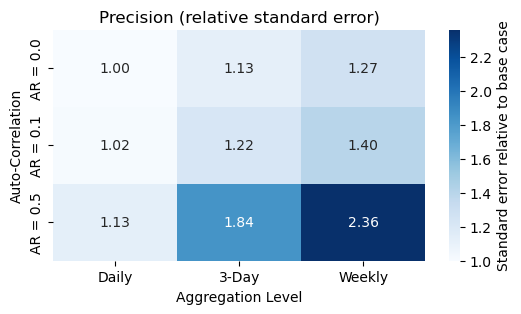

In [ ]:
fig, ax = plt.subplots(figsize=(6,3))
sns.heatmap(se_tbl, annot=True, fmt='.2f', cmap='Blues', ax=ax,
            cbar_kws={'label':'Standard error relative to base case'})
ax.set_xlabel('Aggregation Level')
ax.set_ylabel('Auto-Correlation')
ax.set_title('Precision (relative standard error)')
plt.show()
